# Cars Per Capita in the US
For comparison with cars/capita in Seattle.  This was for a response to a NextDoor comment on a comment I made.  See my [obsidian note](obsidian://open?vault=Obsidian%20Share%20Vault&file=Politics%2FSeattle%2Fclimate%2FVehicles%20per%20Capita%20Seattle) (you must ctrl+click in raw markdown mode)

In [6]:
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

In [7]:
# This data came from: https://www.perplexity.ai/search/how-many-vehicles-per-househol-ooMETWZGTr6fDPiJl0oc0g#3

dfu = pd.read_csv(Path('./dat/orig/usa_vehicles_per_capita_timeseries.csv'))


<Axes: xlabel='Year'>

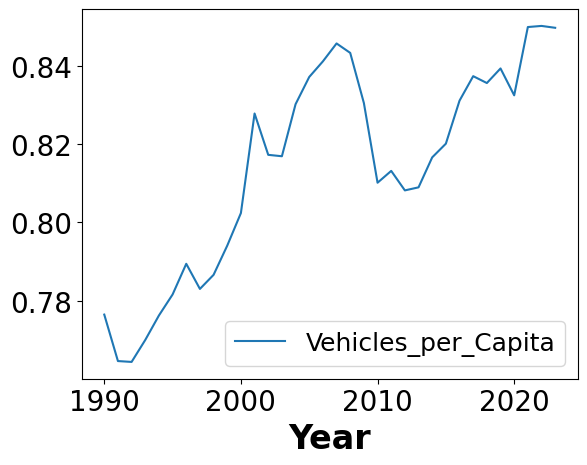

In [8]:
dfu.plot(x='Year', y='Vehicles_per_Capita')

<Axes: xlabel='Year'>

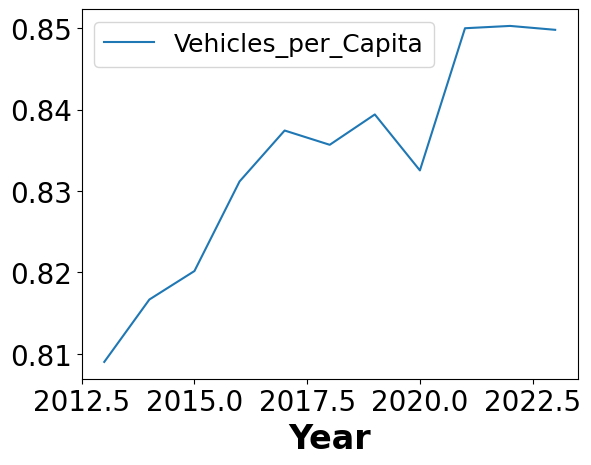

In [9]:
dfu.query('Year>=2013and Year<=2023').plot(x='Year', y='Vehicles_per_Capita')

### Compare to US data

C:\Users\scott\AppData\Local\Temp\ipykernel_85828\1672724121.py:79: UserWarning: You passed a edgecolor/edgecolors ('darkblue') for an unfilled marker ('').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax2.scatter(
C:\Users\scott\AppData\Local\Temp\ipykernel_85828\1672724121.py:84: UserWarning: You passed a edgecolor/edgecolors ('darkblue') for an unfilled marker ('').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax2.scatter(


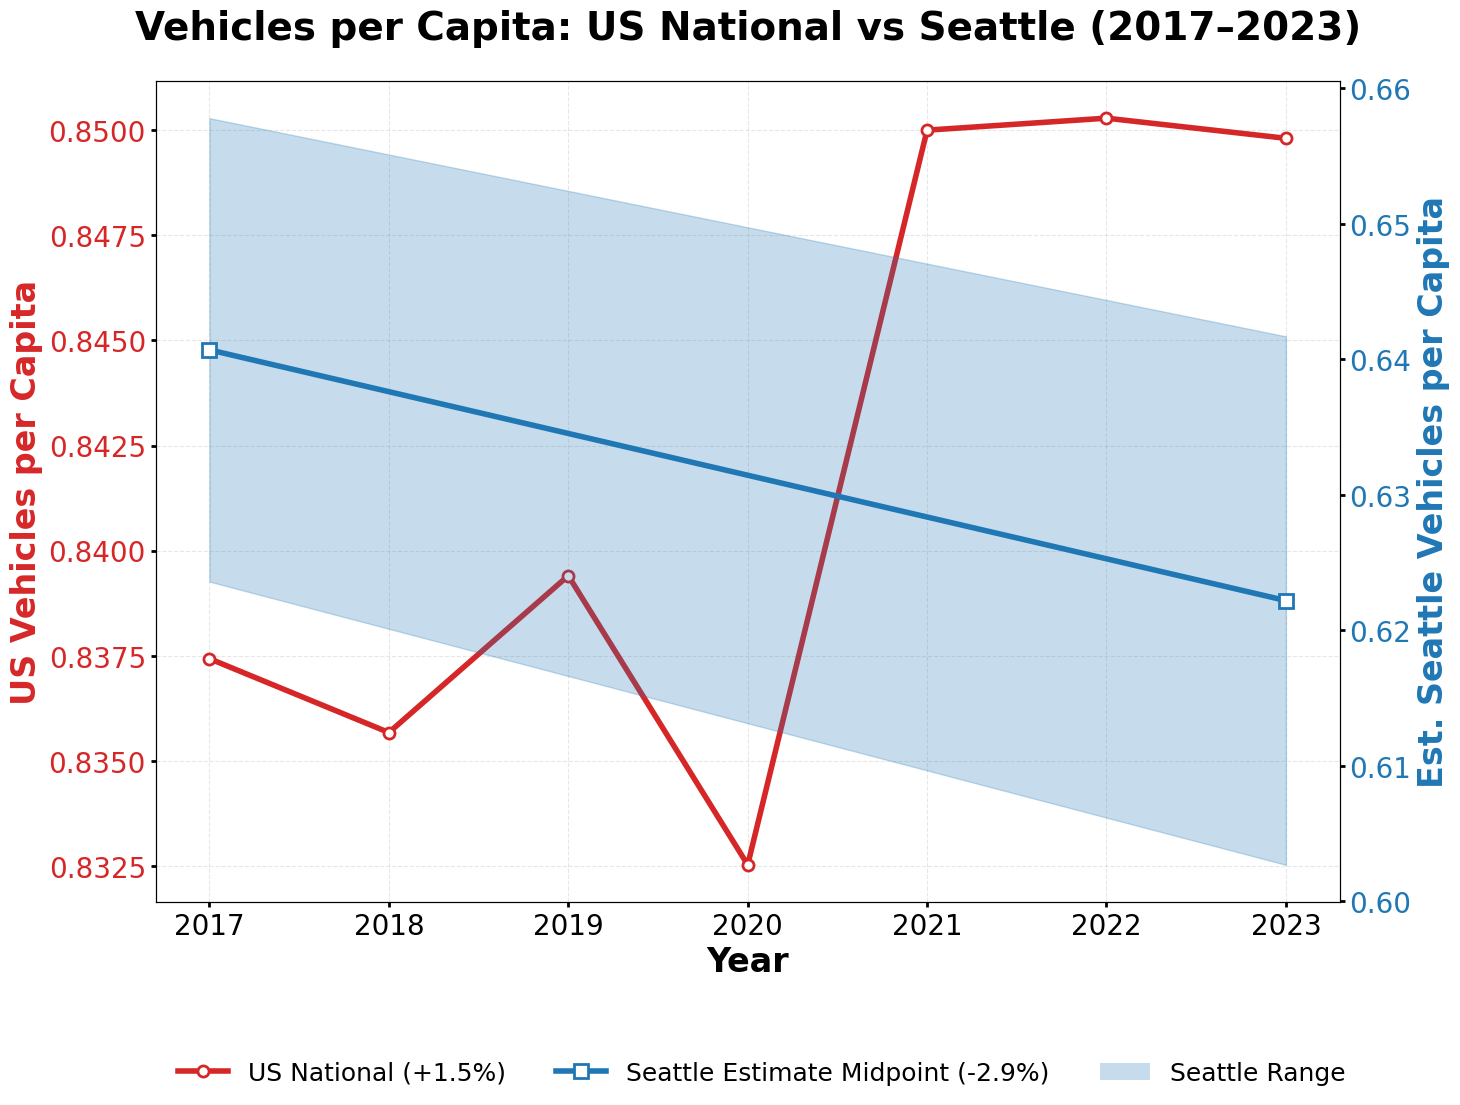

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Set up large bold fonts for presentation
plt.rcParams.update({
    'font.size': 20,
    'axes.labelsize': 24,
    'axes.titlesize': 28,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 18,
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold'
})

def create_us_seattle_comparison_color_swapped():
    """
    Create a double y-axis chart with US in red and Seattle in blue,
    with a compact legend below the plot.
    """
    vehicle_registrations = {
        2017: 272.5, 2018: 273.6, 2019: 276.5,
        2020: 275.9, 2021: 282.2, 2022: 283.4, 2023: 284.6
    }
    us_population_data = {
        2017: 325.4, 2018: 327.4, 2019: 329.4,
        2020: 331.4, 2021: 332.0, 2022: 333.3, 2023: 334.9
    }
    years = list(range(2017, 2024))
    us_vehicles_per_capita = [
        vehicle_registrations[y] / us_population_data[y] for y in years
    ]
    us_df = pd.DataFrame({'Year': years, 'Vehicles_per_Capita': us_vehicles_per_capita})
    us_vpcs_2017 = us_df.query('Year == 2017').Vehicles_per_Capita.iloc[0]
    us_vpcs_2023 = us_df.query('Year == 2023').Vehicles_per_Capita.iloc[0]
    us_change_pct = (us_vpcs_2023-us_vpcs_2017)/us_vpcs_2017 * 100


    seattle_df = pd.DataFrame({
        'Year': [2017, 2023],
        'Low': [0.6236, 0.6027],
        'High': [0.6578, 0.6417]
    })
    seattle_df['Midpoint'] = (seattle_df['Low'] + seattle_df['High']) / 2
    seattle_2017 = seattle_df.query('Year == 2017').Midpoint.iloc[0]
    seattle_2023 = seattle_df.query('Year == 2023').Midpoint.iloc[0]
    seattle_change_pct = (seattle_2023-seattle_2017)/seattle_2017 * 100

    fig, ax1 = plt.subplots(figsize=(15, 11))
    color1, color2 = 'tab:red', 'tab:blue'

    # US line
    ax1.set_xlabel('Year', fontsize=24, fontweight='bold')
    ax1.set_ylabel('US Vehicles per Capita', color=color1, fontsize=24, fontweight='bold')
    ax1.plot(
        us_df['Year'], us_df['Vehicles_per_Capita'],
        color=color1, linewidth=4, marker='o', markersize=8,
        markerfacecolor='white', markeredgewidth=2
    )
    ax1.tick_params(axis='x', labelsize=20, width=2)
    ax1.tick_params(axis='y', labelcolor=color1, labelsize=20, width=2)
    ax1.grid(True, linestyle='--', alpha=0.3)

    # Seattle on twin axis
    ax2 = ax1.twinx()
    ax2.set_ylabel('Est. Seattle Vehicles per Capita', color=color2, fontsize=24, fontweight='bold')
    ax2.fill_between(
        seattle_df['Year'], seattle_df['Low'], seattle_df['High'],
        color=color2, alpha=0.25
    )
    ax2.plot(
        seattle_df['Year'], seattle_df['Midpoint'],
        color=color2, linewidth=4, marker='s', markersize=10,
        markerfacecolor='white', markeredgewidth=2
    )
    ax2.scatter(
        seattle_df['Year'], seattle_df['Low'],
        color=color2, marker='', s=120, edgecolors='darkblue', linewidth=1.5, alpha=0.8        
        #color=color2, marker='v', s=120, edgecolors='darkblue', linewidth=1.5, alpha=0.8
    )
    ax2.scatter(
        seattle_df['Year'], seattle_df['High'],
        color=color2, marker='', s=120, edgecolors='darkblue', linewidth=1.5, alpha=0.8
        #color=color2, marker='^', s=120, edgecolors='darkblue', linewidth=1.5, alpha=0.8
    )
    ax2.tick_params(axis='y', labelcolor=color2, labelsize=20, width=2)

    plt.title(
        'Vehicles per Capita: US National vs Seattle (2017–2023)',
        fontsize=28, fontweight='bold', pad=30
    )

    # Compact legend beneath plot, left-justified

    legend_elements = [
        Line2D([0], [0], color=color1, linewidth=4, marker='o', markersize=8,
               markerfacecolor='white', markeredgewidth=2,
               label=f'US National ({us_change_pct:+.1f}%)'),
        Line2D([0], [0], color=color2, linewidth=4, marker='s', markersize=10,
               markerfacecolor='white', markeredgewidth=2,
               label=f'Seattle Estimate Midpoint ({seattle_change_pct:+.1f}%)'),
        Patch(facecolor=color2, alpha=0.25, label='Seattle Range')
    ]
    plt.legend(
        handles=legend_elements,
        loc='lower left',
        bbox_to_anchor=(0, -0.25),
        ncol=3,
        frameon=False
    )

    plt.subplots_adjust(bottom=0.3)
    plt.tight_layout()
    plt.show()

    return us_df, seattle_df

# Run the function
us_data, seattle_data = create_us_seattle_comparison_color_swapped()
